# 演習2：H₂の電子配置から1 qubitの位相推定へ

演習1の2×2行列を、分子の電子Hamiltonianへ置き換えます。
**電子配置→スピンと固有状態→4×4のブロック→2×2の符号化→回路→測定**の順に進みます。
核間距離0.735 Å、STO-3G、核固定、中性H₂（2電子・2空間軌道）の小さな模型です。

| 本冊で確認するもの | 対応する計算 |
|---|---|
| S₀・S₁・S₂・T₀の違い | 配置の振幅、全スピン、エネルギー |
| S₀・S₂だけなら1 qubitで扱える理由 | 二重占有配置が張る不変な2次元空間 |
| 電子配置から固有状態を作る方法 | 1 qubitのRy回転 |
| QPE・BPE・BPDEの化学での意味 | 絶対エネルギーとS₂−S₀差の推定 |

全数値を内蔵しているため、このNotebookだけで実行できます。IBMアカウント・PySCFは不要です。
4×4行列は状態の説明に使い、位相推定の系は1 qubitに保ちます。
S₁・T₀の位相推定は、次冊の削減なしJW・系4 qubit版へ進んでから扱います。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"

### 実行準備

次セルはNumPy、Qiskit、描画関数を読み込みます。
`draw`は回路図、`draw_measured`は測定を追加した回路図です。
`Statevector`で厳密確率を計算し、shotsの模擬測定とは区別します。

In [2]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector, Operator, DensityMatrix
from IPython.display import display
np.set_printoptions(precision=8, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
TAU = 2*np.pi
ATOL = 1e-10

def draw(qc, fold=110):
    # 回路を画像で表示。数値計算にはこの描画関数は使わない。
    fig = qc.draw(output="mpl", fold=fold)
    display(fig)
    plt.close(fig)

def draw_measured(qc, qubits):
    # 描画用のコピーだけに測定を追加。厳密確率は測定前の回路から計算する。
    measured = qc.copy()
    readout = ClassicalRegister(len(qubits), "readout")
    measured.add_register(readout)
    measured.measure(qubits, readout)
    draw(measured)

def show_probs(probabilities, title, ax=None, shots=None, seed=123):
    p = np.asarray(probabilities, dtype=float)
    m = int(np.log2(len(p)))
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 3))
    x = np.arange(len(p))
    ax.bar(x, p, width=0.65, label="Exact probability", alpha=0.75)
    if shots:
        counts = np.random.default_rng(seed).multinomial(shots, p / p.sum())
        ax.plot(x, counts / shots, "ko", ms=4, label=f"{shots} simulated shots")
    ax.set_xticks(x, [format(i, f"0{m}b") for i in x], rotation=60 if m > 3 else 0)
    ax.set(xlabel="Measured bits (MSB ... LSB)", ylabel="Probability", title=title)
    ax.legend(fontsize=8)
    return ax


print("Python", sys.version.split()[0], "NumPy", np.__version__, "Qiskit", qiskit.__version__)

Python 3.12.7 NumPy 2.4.6 Qiskit 2.4.1


## 0．二つの空間軌道と四つのスピン軌道

STO-3Gでは各H原子に1個ずつ基底関数があり、RHF計算から二つの空間軌道を作ります。
結合性軌道を$g=\sigma_g$、反結合性軌道を$u=\sigma_u$と書きます。
それぞれにα（↑）、β（↓）のスピンがあり、計4スピン軌道です。
占有ビットの順序を$(q_0,q_1,q_2,q_3)=(g\alpha,u\alpha,g\beta,u\beta)$、
表示ケットを$|q_3q_2q_1q_0\rangle$とします。

```text
                 Dg            Du            O1            O2
u (反結合性)    [    ]        [↑↓ ]         [ ↑ ]         [ ↓ ]
g (結合性)      [↑↓ ]         [    ]        [ ↓ ]         [ ↑ ]
```

| 配置名 | 意味 | 占有ケット |
|---|---|---|
| $D_g$ | gを二重占有（RHF配置） | $|0101\rangle$ |
| $D_u$ | uを二重占有（二重励起配置） | $|1010\rangle$ |
| $O_1$ | gβとuαを一つずつ占有 | $|0110\rangle$ |
| $O_2$ | gαとuβを一つずつ占有 | $|1001\rangle$ |

いずれも電子数2、$M_S=(N_\alpha-N_\beta)/2=0$です。
この4配置のほかにgα・uα、gβ・uβの配置があり、電子数2の空間全体は$\binom42=6$次元です。
各ケットは反対称化済みのSlater行列式です。電子を区別できる粒子として並べた積ではありません。
「配置」は占有の基底、「分子の固有状態」はその線形結合です。

## 1．S₀・S₁・S₂・T₀は何が違うか

全スピン$S$に対し$\hat S^2$の固有値は$S(S+1)$（$\hbar=1$）です。
一重項はS=0、三重項はS=1。S₀/S₁/S₂の添字は**一重項の中でのエネルギー順位**です。
T₀は本教材で最低三重項を指し、計算ではその$M_S=0$成分を使います（コード名は`T`）。
最低三重項をT₁と呼ぶ流儀もあります。ここでは「三重項の順位」と「スピン射影M_S」を分けて考えます。

$$\begin{aligned}
|S_0\rangle&=\cos(\theta/2)|D_g\rangle+\sin(\theta/2)|D_u\rangle,\\
|S_2\rangle&=-\sin(\theta/2)|D_g\rangle+\cos(\theta/2)|D_u\rangle,\\
|S_1\rangle&=(|O_1\rangle+|O_2\rangle)/\sqrt2,\\
|T_0,M_S=0\rangle&=(|O_1\rangle-|O_2\rangle)/\sqrt2.
\end{aligned}$$

ここでθは後でHamiltonianから決まる混合角です。
最後の二つの±は、上で固定した行列式・軌道の位相規約によるものです。
電子1・2のスピン関数で書く一重項$(\alpha\beta-\beta\alpha)/\sqrt2$の符号を、
反対称化を含む行列式の係数へそのまま移してはいけません。後で$S^2=0,2$を数値照合します。

| 状態 | 配置の特徴 | 全スピン | この距離でのエネルギー順位 |
|---|---|---:|---|
| S₀ | 主にDg、少量のDu | 0 | 最低 |
| T₀ | O1とO2、相対符号− | 1 | S₀より上、S₁より下 |
| S₁ | O1とO2、相対符号＋ | 0 | 三重項とは別の状態 |
| S₂ | 主にDu、少量のDg | 0 | 本模型の最高一重項 |

三重項には$M_S=-1,0,+1$の3成分があります。スピンに依存しないこのHでは同じエネルギーです。
$M_S=0$の三重項を「二電子がどちらも↑の配置」と説明することはできません。

### 課題1：占有とスピンを区別する

1. O1、O2はそれぞれS₁またはT₀そのものか。
2. S₁とT₀を占有ビットの測定確率だけで区別できるか。
3. 同じM_S=0なら同じSか。

<details><summary>解答例</summary>

1. それぞれは行列式であり、この場合はS₁とT₀の重ね合わせです。固有状態はO1±O2です。
2. 両状態ともO1、O2が各1/2で、占有確率だけでは区別できません。相対符号とS²の測定に違いがあります。
3. M_S=0でもS=0とS=1を含みます。S₁はS²=0、T₀はS²=2です。

</details>

## 2．配置を基底にした4×4行列で違いを見る

基底を$(D_g,D_u,O_1,O_2)$の順に並べます。電子Hamiltonianは、丸めて
$$H_{M_S=0}=\begin{pmatrix}
-1.836968&0.180931&0&0\\
0.180931&-0.245218&0&0\\
0&0&-1.063653&0.180931\\
0&0&0.180931&-1.063653
\end{pmatrix}\quad\text{Hartree}.$$

左上が二重占有配置、右下が開殻配置のブロックです。
左上の非対角項がHF配置DgとDuを混ぜ、S₀・S₂を作ります。
右下の対角要素は等しいので、固有ベクトルはO1±O2です。
対称結合のS₁は$-1.063653+0.180931$、反対称結合のT₀は$-1.063653-0.180931$の電子エネルギーです。

この基底で$S^2$は左上が0、右下が$\begin{pmatrix}1&-1\\-1&1\end{pmatrix}$です。
次セルでは二つのブロックを対角化し、エネルギー固有方程式とS²を照合します。
図の**符号付き振幅**と表のエネルギーを見てください。全エネルギーには核間反発0.7199689944 Haを加えます。

State   total energy / Ha   S^2    amplitudes (Dg,Du,O1,O2)
S0        -1.1373060358   0.0 [ 0.9937604  -0.11153594  0.          0.        ]
S1        -0.1627531558   0.0 [0.         0.         0.70710678 0.70710678]
S2         0.4950577416   0.0 [0.11153594 0.9937604  0.         0.        ]
T         -0.5246155554   2.0 [ 0.          0.          0.70710678 -0.70710678]


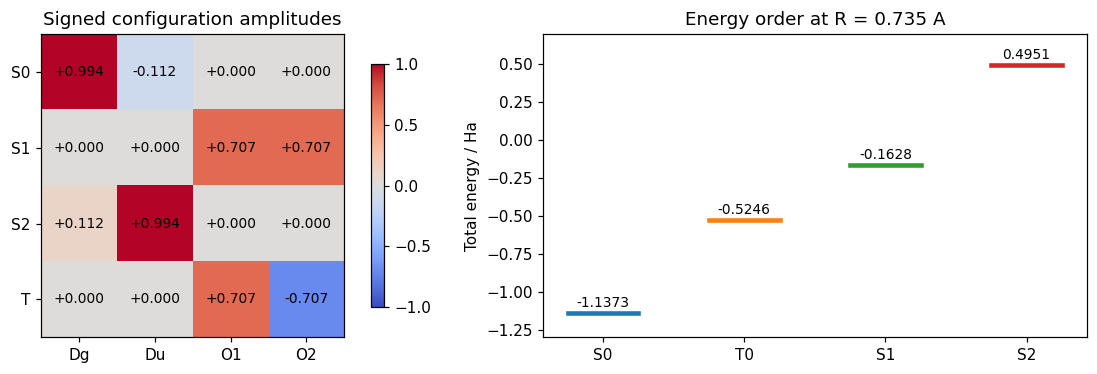

In [3]:
H_MS0 = np.array([[-1.836967991202984, 0.18093119978423136, 3.562995389700622e-16, 3.562995389700622e-16], [0.18093119978423136, -0.24521829183026772, 1.4261056136209557e-16, 1.4261056136209557e-16], [5.435453356799236e-17, 4.445555667641654e-16, -1.0636533500290954, 0.18093119978423136], [5.435453356799236e-17, 4.445555667641654e-16, 0.18093119978423136, -1.0636533500290954]], dtype=float)
# 独立したJW教材から取り出した中性・Ms=0ブロック。微小なゼロ要素は保持する。
S2_MS0 = np.zeros((4,4))
S2_MS0[2:,2:] = [[1,-1],[-1,1]]
energies_closed, vectors_closed = np.linalg.eigh(H_MS0[:2,:2])
for k in range(2):
    if vectors_closed[np.argmax(abs(vectors_closed[:,k])),k] < 0:
        vectors_closed[:,k] *= -1
STATES_MS0 = {'S0':np.r_[vectors_closed[:,0],0.,0.],
              'S1':np.array([0,0,1,1])/np.sqrt(2),
              'S2':np.r_[vectors_closed[:,1],0.,0.],
              'T':np.array([0,0,1,-1])/np.sqrt(2)}
ENERGIES_MS0 = {name:float(psi@H_MS0@psi) for name,psi in STATES_MS0.items()}
print('State   total energy / Ha   S^2    amplitudes (Dg,Du,O1,O2)')
for name,psi in STATES_MS0.items():
    energy=ENERGIES_MS0[name]
    spin=float(psi@S2_MS0@psi)
    np.testing.assert_allclose(H_MS0@psi,energy*psi,atol=1e-12)
    np.testing.assert_allclose(S2_MS0@psi,(2 if name=='T' else 0)*psi,atol=1e-12)
    print(f'{name:4s} {energy+.7199689944489797:18.10f} {spin:5.1f}',psi)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
names=['S0','S1','S2','T']
amplitudes=np.array([STATES_MS0[name] for name in names])
im=axes[0].imshow(amplitudes,cmap='coolwarm',vmin=-1,vmax=1)
axes[0].set_xticks(range(4),['Dg','Du','O1','O2']);axes[0].set_yticks(range(4),names)
axes[0].set_title('Signed configuration amplitudes')
for i in range(4):
    for j in range(4):axes[0].text(j,i,f'{amplitudes[i,j]:+.3f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=axes[0],shrink=.8)
for i,name in enumerate(['S0','T','S1','S2']):
    energy=ENERGIES_MS0[name]+.7199689944489797
    axes[1].plot([i-.25,i+.25],[energy,energy],lw=3)
    axes[1].text(i,energy+.04,f'{energy:.4f}',ha='center',fontsize=9)
axes[1].set_xticks(range(4),['S0','T0','S1','S2'])
axes[1].set(ylabel='Total energy / Ha',title='Energy order at R = 0.735 A',ylim=(-1.3,.7))
plt.tight_layout();plt.show();plt.close(fig)

## 3．S₀・S₂だけなら、なぜ1 qubitで足りるか

H₂の反転対称性により、Dg・Duは偶、O1・O2は奇の空間対称性を持ちます。
g×gとu×uは偶、g×uは奇なので、この固定模型のHは両ブロックを結びません。
S₁も一重項ですが**別の空間対称性のブロック**にあります。一重項という条件だけでは除外できません。

二重占有空間$\mathcal V=\mathrm{span}\{D_g,D_u\}$は、Hを作用させても外へ出ない不変部分空間です。
その2次元だけを、論理qubitの2次元へ対応させます。
$$V|0\rangle_L=|D_g\rangle,\quad V|1\rangle_L=|D_u\rangle,\quad
H_L=V^\dagger H_{M_S=0}V.$$
$V=\begin{pmatrix}1&0\\0&1\\0&0\\0&0\end{pmatrix}$とすれば
$H_{M_S=0}V=VH_L$であり、$e^{-iH_{M_S=0}t}V=Ve^{-iH_Lt}$です。
このブロック内では厳密な符号化です。電子間相互作用を捨てたり、片方の電子を消したりしているわけではありません。

```text
4スピン軌道のFock空間: 16次元   (削減なしJWでは4 qubit)
             ↓ 電子数2: 6次元
             ↓ Ms=0: 4次元 = {Dg,Du} ⊕ {O1,O2}
             ↓ 二重占有の不変ブロックを選択
          2次元 = {Dg,Du}  ↔  {|0>_L, |1>_L}: 1 qubit
```

演習3への接続に使う4占有ビットでは、$|0\rangle_L\leftrightarrow|0101\rangle$、
$|1\rangle_L\leftrightarrow|1010\rangle$です。元の自習教材はParity変換を介して同じブロックを得ます。
本冊では上の等長写像Vで直接対応を示します。

### 課題2：表現できる状態の範囲

1. 論理$\alpha|0\rangle_L+\beta|1\rangle_L$は、分子ではどの状態か。
2. 論理|1⟩を準備すればS₁またはS₂になるか。
3. この1 qubitでS₁・T₀も含む四つの直交状態を同時に表現できるか。

<details><summary>解答例</summary>

1. αDg+βDuです。任意の二電子状態ではなく、選んだ2配置内の状態です。
2. |1⟩Lは配置Duです。S₁は別ブロック、S₂は主にDuですがDgも混ざるため、どちらそのものでもありません。
3. 1 qubitの次元は2なので、四つの直交状態を同時には保持できません。
本冊のS₀/S₂の符号化を使ってS₁/T₀を計算することはできません。
4状態の抽象的な符号化なら2 qubitで可能ですが、次冊では全Fock空間を残すJWの4 qubit表現を使います。

</details>

### 3.1．2×2 Hamiltonianと位相の変数を定義する

以下のHはVで取り出した電子Hamiltonianです。
$$H=cI-zZ+xX,\quad c=\tfrac12(H_{00}+H_{11}),\quad
z=\tfrac12(H_{11}-H_{00}),\quad x=H_{01}.$$
$\rho=\sqrt{x^2+z^2}$、$\theta=-\operatorname{atan2}(x,z)$とすると、
$R_y(\theta)^T H R_y(\theta)=\operatorname{diag}(c-\rho,c+\rho)$です。

| コード | 意味 |
|---|---|
| `zero`, `one` | 配置Dg、Duの論理表現 |
| `g`, `e` | S₀、S₂の論理振幅 |
| `E`, `ENUC` | 電子固有エネルギー、核間反発 |
| `DT`, `L` | 基本時間Δt=1原子単位、反復数 |
| `PHASES` | −EΔt/(2π)で得る位相 |
| `GAP` | 位相差を周期1で表した値 |
| `ENERGY_GAP` | 正のS₂−S₀差、Hartree |

位相とエネルギーのGAPは同じ数ではありません。符号と周期の換算は第5節で確認します。
次セルではHを対角化し、HFの重なりと参照値を表示します。

In [4]:
H = np.array([[-1.836967991202984, 0.18093119978423136],
              [0.18093119978423136, -0.24521829183026772]])
ENUC = 0.7199689944489797
DT = 1.0
c = np.trace(H)/2
z = (H[1,1]-H[0,0])/2
x = H[0,1]
rho_h = np.hypot(z,x)
theta = -np.arctan2(x,z)
def ry(angle):
    co, si = np.cos(angle/2), np.sin(angle/2)
    return np.array([[co,-si],[si,co]], complex)
R = ry(theta)
E = np.array([c-rho_h, c+rho_h])
PHASES = -E*DT/TAU
GAP = (PHASES[1]-PHASES[0]) % 1
ENERGY_GAP = E[1]-E[0]
zero = np.array([1,0], complex)  # 論理HF配置。固有状態ではない。
one = np.array([0,1], complex)
g, e = R[:,0], R[:,1]
psi_mixed = np.sqrt(.75)*g + np.sqrt(.25)*e
HF_WEIGHTS = abs(R.conj().T @ zero)**2

def u_power(L, phases=PHASES):
    return R @ np.diag(np.exp(1j*TAU*L*np.asarray(phases))) @ R.conj().T

def phase_to_total(phi): return -TAU*np.asarray(phi)/DT + ENUC
def phase_to_gap(delta): return TAU*(1-np.asarray(delta))/DT
assert np.allclose(R.T@H@R, np.diag(E), atol=ATOL)
assert np.allclose(phase_to_total(PHASES), E+ENUC)
assert np.isclose(phase_to_gap(GAP), ENERGY_GAP)
print("H electronic =\n", H)
print("S0,S2 total energies:", E+ENUC)
print("S0,S2 phases:", PHASES, "phase gap modulo 1:", GAP)
print("S2-S0 gap (Hartree):", ENERGY_GAP)
print("HF total expectation:", H[0,0]+ENUC, "HF eigenstate weights:", HF_WEIGHTS)
print("theta:", theta)

H electronic =
 [[-1.83696799  0.1809312 ]
 [ 0.1809312  -0.24521829]]
S0,S2 total energies: [-1.13730604  0.49505774]
S0,S2 phases: [0.2955945  0.03579574] phase gap modulo 1: 0.7402012359071664
S2-S0 gap (Hartree): 1.6323637773715078
HF total expectation: -1.1169989967540044 HF eigenstate weights: [0.98755973 0.01244027]
theta: -0.22353699826765971


## 4．配置からS₀・S₂を作る回路

$R_y(\theta)=\begin{pmatrix}\cos(\theta/2)&-\sin(\theta/2)\\
\sin(\theta/2)&\cos(\theta/2)\end{pmatrix}$なので、二つの列が固有状態です。

```text
S0: |0>_L ─────────Ry(θ)──→ cos(θ/2)|0> + sin(θ/2)|1>
S2: |0>_L ──X──────Ry(θ)──→ -sin(θ/2)|0> + cos(θ/2)|1>
```

θ≈−0.223537で、S₀は約$0.99376D_g-0.11154D_u$です。
HFはDg一配置で、S₀と同じではありません。非対角項があるためH|Dg⟩はDu成分を持ちます。
重なり$|\langle S_0|HF\rangle|^2\approx0.98756$、残り約0.01244はS₂です。

次セルで回路振幅、4配置への埋め込み、固有方程式を照合します。
1 qubitの回転は**二つの電子配置の係数を変える**操作で、実在の片方の電子スピンを回すという意味ではありません。

S0 logical amplitudes: [ 0.9937604 +0.j -0.11153594+0.j] configuration amplitudes: [ 0.9937604 +0.j -0.11153594+0.j  0.        +0.j  0.        +0.j]
S2 logical amplitudes: [0.11153594+0.j 0.9937604 +0.j] configuration amplitudes: [0.11153594+0.j 0.9937604 +0.j 0.        +0.j 0.        +0.j]
HF variance: 0.03273609905536157 Ha^2


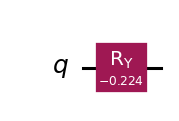

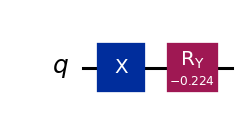

In [5]:
prep_g = QuantumCircuit(1); prep_g.ry(theta,0)
prep_e = QuantumCircuit(1); prep_e.x(0); prep_e.ry(theta,0)
draw(prep_g); draw(prep_e)
V=np.eye(4)[:,:2]
np.testing.assert_allclose(V.T@H_MS0@V,H,atol=1e-12)
np.testing.assert_allclose(H_MS0@V,V@H,atol=1e-12)
for name,qc,psi in [('S0',prep_g,g),('S2',prep_e,e)]:
    actual=Statevector.from_instruction(qc).data
    np.testing.assert_allclose(actual,psi,atol=ATOL)
    np.testing.assert_allclose(V@actual,STATES_MS0[name],atol=ATOL)
    energy=float(np.vdot(psi,H@psi).real)
    np.testing.assert_allclose(H@psi,energy*psi,atol=ATOL)
    print(name,'logical amplitudes:',actual,'configuration amplitudes:',V@actual)
print('HF variance:',float(np.vdot(zero,H@H@zero).real-(H[0,0])**2),'Ha^2')

### 課題3：配置・固有状態・回路を結ぶ

1. S₂を作る回路にXだけを残すと、どの配置を作るか。
2. HFのエネルギー期待値とS₀の固有エネルギーは同じか。
3. 二つの準備回路の出力が直交することを、Ryの列または内積で確認する。

<details><summary>解答例</summary>

1. 論理|1⟩、つまりDuを作ります。RyがないのでS₂のDg成分を作れません。
2. HF全エネルギーは約−1.116999 Ha、S₀は約−1.137306 Haで、異なります。
HFは固有状態ではなく分散も非零です。混合によって模型内の基底エネルギーが下がります。
3. Ryはユニタリなので列が直交し、⟨S₀|S₂⟩=0です。二つを4配置へ写してもV†V=Iにより内積は変わりません。

</details>

## 5．時間発展と干渉：行列版との符号の違い

演習1は$U=e^{+2\pi iK}$、分子では$U=e^{-iH\Delta t}$です。
$$\phi_j=-E_j^{\rm el}\Delta t/(2\pi)\pmod1,\qquad t=L\Delta t.$$
本模型は既知の電子エネルギー探索区間−2<E_el<0 Haにあり、Δt=1では
$E_{\rm total}=-2\pi\phi/\Delta t+E_{\rm nuc}$で周期をほどけます。

| 状態 | 全エネルギー / Ha | 位相（1周単位） |
|---|---:|---:|
| S₀ | −1.1373060358 | 約0.29559450 |
| S₂ | ＋0.4950577416 | 約0.03579574 |

S₂の方が高エネルギーでも位相は小さくなります。
この1 qubitでは発展を厳密に
$$U^L=e^{-ict}R_y(\theta)R_z(-2\rho t)R_y(-\theta)$$
と作れます。回路は右端の演算子から実行します。

```text
s: ──Ry(-θ)──Rz(-2ρt)──Ry(θ)──   (全体位相 exp(-ict) も保持)

a: |0> ──H──●──────P(β)──H──M
            │
s: |Sj> ───[U^L]─────────────
```

干渉確率は$[1+\cos(2\pi L\phi_j+\beta)]/2$。
位相候補εならβ=−2πLε、**電子エネルギー候補**ε_Eならβ=ε_E tです。
制御Uではexp(−ict)が補助の一方の枝だけに付き、相対位相になるため保持します。
次セルは回転回路と厳密行列、干渉確率と余弦式を照合します。

Constant kept: 0.35871190082516224 omitted: 0.8425039119871764


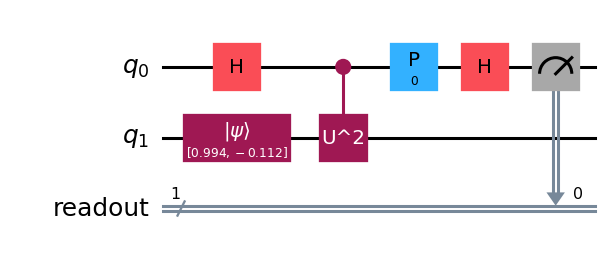

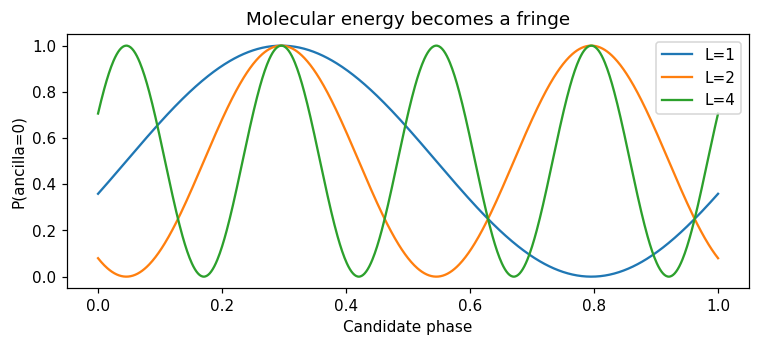

In [6]:
def evolution_gate(L, keep_constant=True):
    t = L*DT
    qc = QuantumCircuit(1, name=f"U^{L}")
    qc.ry(-theta,0); qc.rz(-2*rho_h*t,0); qc.ry(theta,0)
    if keep_constant: qc.global_phase = -c*t
    return qc.to_gate()

def ramsey_circuit(psi, L=1, beta=0., keep_constant=True):
    qc = QuantumCircuit(2)
    qc.initialize(psi,1); qc.h(0)
    qc.append(evolution_gate(L,keep_constant).control(), [0,1])
    qc.p(beta,0); qc.h(0)
    return qc

def ancilla_zero(qc):
    return float(Statevector.from_instruction(qc).probabilities([0])[0])

def bpe_probability(weights,L,beta):
    amp = np.dot(weights,np.exp(1j*TAU*L*PHASES))
    return .5*(1+np.real(np.exp(1j*beta)*amp))

for L in [1,2,5,32]:
    assert np.allclose(Operator(evolution_gate(L)).data,u_power(L),atol=ATOL)
draw_measured(ramsey_circuit(g,2),[0])
candidates = np.linspace(0,1,801)
fig,ax = plt.subplots(figsize=(8,3))
for L in [1,2,4]:
    ax.plot(candidates,bpe_probability([1,0],L,-TAU*L*candidates),label=f"L={L}")
    for beta in [0,.37,-1.2]:
        assert np.isclose(ancilla_zero(ramsey_circuit(g,L,beta)),bpe_probability([1,0],L,beta),atol=ATOL)
ax.set(xlabel="Candidate phase",ylabel="P(ancilla=0)",title="Molecular energy becomes a fringe")
ax.legend(); plt.show()
print("Constant kept:",ancilla_zero(ramsey_circuit(g)),"omitted:",ancilla_zero(ramsey_circuit(g,keep_constant=False)))
assert not np.isclose(ancilla_zero(ramsey_circuit(g)),ancilla_zero(ramsey_circuit(g,keep_constant=False)))

### 課題4：発展時間と定数項

1. 候補位相ε∈[0,1)を掃引し、L=1、2、4にするとピークはいくつか。
2. 制御UからcIを省いた場合、BPEで得る値は正しい分子エネルギーか。
3. U⁵は位相の第5桁を読む操作か。

<details><summary>解答例</summary>

1. 順に1、2、4個です。候補の周期は1/Lで、長時間だけでは周期の別候補が残ります。
2. H−cIの固有エネルギーを読むことになり、そのままでは正しい絶対エネルギーではありません。
両枝へ共通の時間発展をかけるBPDEでは共通位相は差から消えます。
3. L=5回、t=5Δtの時間発展であり、第5桁ではありません。

</details>

## 6．QPE：同じ回路から、分子の固有エネルギーを読む

```text
補助m個: |0...0> ──H⊗m──制御 U^(2^r)──IQFT──測定 y → φ=y/2^m → E_total
系1個  : |Sj>   ─────────Uの作用───────────
```

演習1と同じ分布$P(y|\phi)=|2^{-m}\sum_{k=0}^{2^m-1}e^{2\pi ik(\phi-y/2^m)}|^2$です。
分子の位相は有限二進数で正確に表せないため、厳密準備でも出力が周囲の格子へ広がります。
HF入力なら$P(y)=w_0P(y|\phi_0)+w_2P(y|\phi_2)$で、HFの期待値が一つ出るわけではありません。

次セルの`QPE_BITS`を変え、厳密S₀・HF・S₂成分25%の入力を比較します。
系は1 qubitのまま、補助の数と制御Uのべきが増えます。
図の赤い点線はFCIの模型内の参照エネルギーで、実験値ではありません。

HF weights S0,S2: [0.98755973 0.01244027]
Energy grid spacing / Ha: 0.09817477042468103


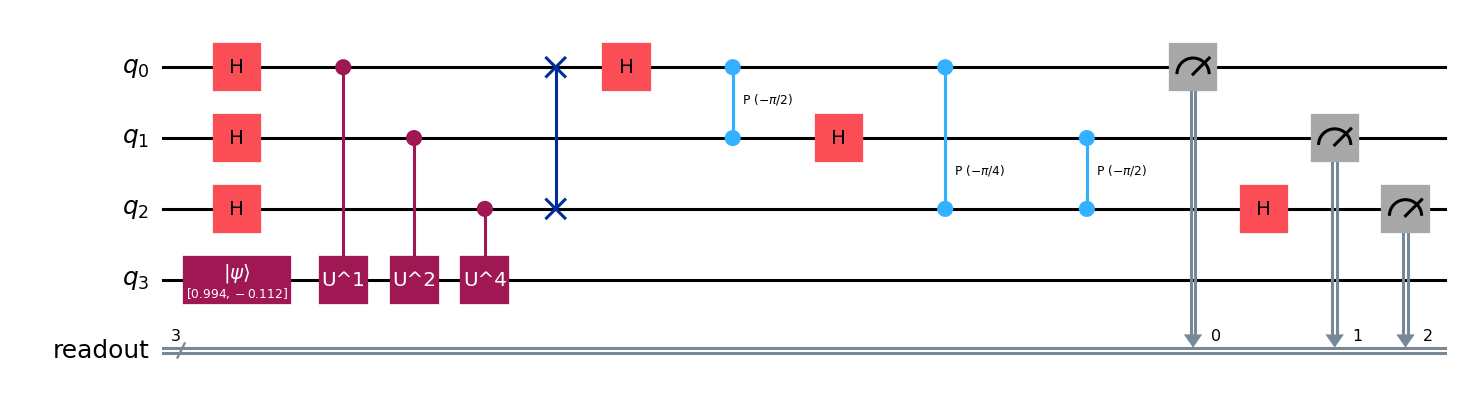

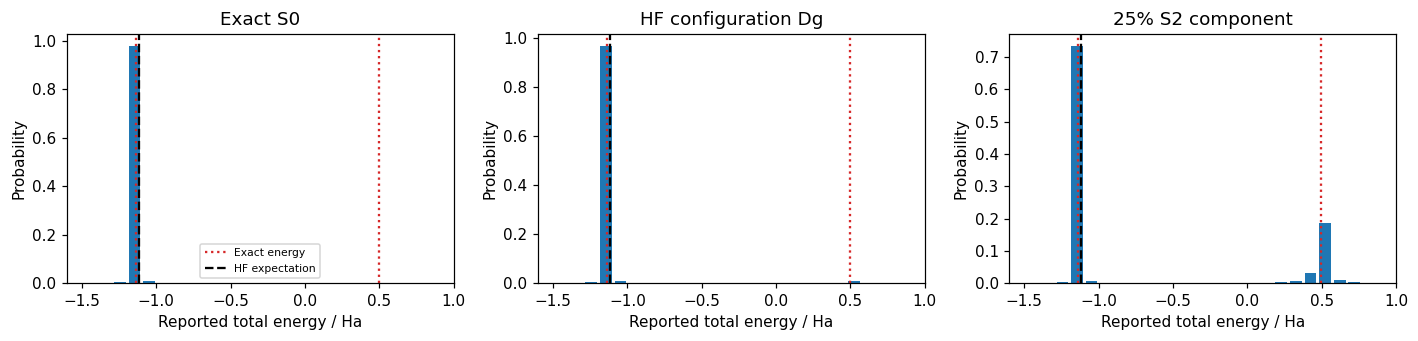

In [7]:
def inverse_qft(m):
    qc = QuantumCircuit(m, name="QFT_dg")
    for j in range(m // 2):
        qc.swap(j, m - 1 - j)
    for j in range(m):
        for ell in range(j):
            qc.cp(-np.pi / 2**(j - ell), j, ell)
        qc.h(j)
    return qc

def qpe_circuit(psi, m=3, phases=PHASES):
    qc = QuantumCircuit(m + 1)
    qc.initialize(psi, m)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(u_power(2**r, phases), label=f"U^{2**r}").control(), [r, m])
    qc.compose(inverse_qft(m), list(range(m)), inplace=True)
    return qc

def qpe_distribution(psi, m=3, phases=PHASES):
    state = Statevector.from_instruction(qpe_circuit(psi, m, phases))
    return state.probabilities(list(range(m)))


def qpe_formula(phi,m):
    M=2**m
    amp=np.mean(np.exp(1j*TAU*np.outer(np.arange(M),phi-np.arange(M)/M)),axis=0)
    return abs(amp)**2

QPE_BITS=6  # 3, 6, 8を比較
M=2**QPE_BITS;xx=np.arange(M)
np.testing.assert_allclose(Operator(inverse_qft(QPE_BITS)).data,
    np.exp(-1j*TAU*np.outer(xx,xx)/M)/np.sqrt(M),atol=ATOL)
draw_measured(qpe_circuit(g,m=3),[0,1,2])  # 図は読みやすい3補助版
fig,axes=plt.subplots(1,3,figsize=(13,3.2))
for ax,state,label in zip(axes,[g,zero,psi_mixed],['Exact S0','HF configuration Dg','25% S2 component']):
    p=qpe_distribution(state,m=QPE_BITS)
    w=abs(R.T@state)**2
    expected=sum(wj*qpe_formula(phi,QPE_BITS) for wj,phi in zip(w,PHASES))
    np.testing.assert_allclose(p,expected,atol=ATOL)
    energies=phase_to_total(np.arange(M)/M)
    ax.bar(energies,p,width=TAU/(M*DT)*.8)
    for Ej in E+ENUC:ax.axvline(Ej,color='C3',ls=':',label='Exact energy' if Ej==E[0]+ENUC else None)
    ax.axvline(H[0,0]+ENUC,color='black',ls='--',label='HF expectation')
    ax.set(xlim=(-1.6,1),xlabel='Reported total energy / Ha',ylabel='Probability',title=label)
axes[0].legend(fontsize=7);plt.tight_layout();plt.show();plt.close(fig)
print('HF weights S0,S2:',HF_WEIGHTS)
print('Energy grid spacing / Ha:',TAU/(M*DT))

### 課題5：QPEの確率を解釈する

1. HF入力の約1.24%の成分はS₁か。
2. QPE_BITSを増やせばHFが厳密S₀へ変わるか。
3. 厳密S₀なのに有限mで参照値ぴったりの出力にならない理由は何か。

<details><summary>解答例</summary>

1. 残りは同じブロックのS₂です。S₁・T₀の振幅はこの符号化にはありません。
2. 元のHFの成分の重みは変わりません。増えるのは位相・エネルギー格子の分解能です。
十分な分解能で補助の結果に条件付ければ対応固有状態に近づきますが、無条件の全入力がS₀になる操作ではありません。
3. 分子の位相がy/2^mの格子に載らないためです。時間発展の近似誤差や準備誤差とは別の有限ビット効果です。

</details>

## 7．BPE：S₀の位相の山をGaussianフィットして更新する

`01`と同じ手順です。候補位相$\epsilon$に対して$\beta=-2\pi L\epsilon$を設定し、補助0の頻度を走査します。
$$P_0(\epsilon)=\frac{1+\cos[2\pi L(\phi_{S_0}-\epsilon)]}{2},\qquad
 g(\epsilon)=A\exp[-(\epsilon-m)^2/(2w)].$$
事前$N(\mu,v)$とフィットGaussianの積から
$$v'=(1/v+1/w)^{-1},\qquad \mu'=v'(\mu/v+m/w)$$
と更新し、次の事前へ渡します。$w$は山の幅の二乗で、フィット中心の統計的な分散ではありません。

粗い事前$\mu=0.32,\sigma=0.08$から、一つの山を追います。全域から未知の枝を探す例ではありません。
$L=\max(1,\lfloor0.20/\sigma\rfloor)$、半幅$h=\min(2\sigma,1/(4L))$として$[\mu-h,\mu+h]$に21候補を置きます。
真値を計画・更新に使いません。余弦の山のGaussian近似なので、初期探索窓から真の山が外れる場合や、状態が混ざる場合は推定が偏り得ます。
次の補助セルは`01`と同じ関数です。

In [8]:
from scipy.optimize import curve_fit

def single_phase_model(phi, L, beta):
    return .5*(1+np.cos(TAU*L*phi+beta))

def gaussian(x, amplitude, mean, sd):
    return amplitude*np.exp(-.5*((np.asarray(x)-mean)/sd)**2)

def choose_scan(mu, variance, points=21):
    if not np.isfinite(mu) or not np.isfinite(variance) or variance <= 0:
        raise ValueError('有限の中心と正の分散が必要です')
    sd=np.sqrt(variance)
    L=max(1, int(np.floor(.20/sd)))
    halfwidth=min(2*sd,1/(4*L))
    eps=np.linspace(mu-halfwidth, mu+halfwidth, points)
    return L,eps

def gaussian_round(signal, mu, variance, rng, mode='exact', shots=256):
    # signalは実際の回路から確率を返す。真値を計画・更新へ渡さない。
    if mode not in ('exact','shots'):
        raise ValueError("modeは'exact'または'shots'")
    if not isinstance(shots, (int,np.integer)) or shots <= 0:
        raise ValueError('shotsは正の整数')
    L,eps=choose_scan(mu,variance)
    beta=-TAU*L*eps
    exact=np.array([signal(L,float(b)) for b in beta])
    if np.any(exact < -ATOL) or np.any(exact > 1+ATOL):
        raise ValueError('回路確率が範囲外です')
    exact=np.clip(exact,0,1)
    counts=rng.binomial(shots,exact) if mode=='shots' else None
    observed=counts/shots if counts is not None else exact.copy()
    span=eps[-1]-eps[0]
    params,_=curve_fit(gaussian,eps,observed,
        p0=[1.,mu,np.sqrt(variance)],
        bounds=([.01,eps[0],span*.01],[2.,eps[-1],span*10]),maxfev=20000)
    amplitude,m,sd=params
    w=sd**2
    new_v=1/(1/variance+1/w)
    new_mu=new_v*(mu/variance+m/w)
    fitted=gaussian(eps,*params)
    return dict(prior_mu=mu,prior_v=variance,L=L,eps=eps,beta=beta,
        exact=exact,observed=observed,counts=counts,shots=shots,mode=mode,
        amplitude=amplitude,fit_mu=m,fit_v=w,posterior_mu=new_mu,
        posterior_v=new_v,rmse=float(np.sqrt(np.mean((observed-fitted)**2))))


def gaussian_updates(signal, initial_mu, initial_sd, rounds=5, mode='shots', shots=256, seed=20261108):
    rng=np.random.default_rng(seed)
    mu,v=initial_mu,initial_sd**2
    rows=[]
    for _ in range(rounds):
        row=gaussian_round(signal,mu,v,rng,mode,shots)
        rows.append(row)
        mu,v=row['posterior_mu'],row['posterior_v']
    return rows

def plot_updates(rows, truth, title, xlabel='Phase or phase gap / cycles'):
    if not rows:
        print('No updates');return
    mu,v=rows[0]['prior_mu'],rows[0]['prior_v']
    final=rows[-1]
    final_mu,final_sd=final['posterior_mu'],np.sqrt(final['posterior_v'])
    density=lambda x,m,v: gaussian(x,1/np.sqrt(TAU*v),m,np.sqrt(v))
    fig,axes=plt.subplots(1,2,figsize=(11,3))
    x=np.linspace(min(mu-4*np.sqrt(v),truth-.02),max(mu+4*np.sqrt(v),truth+.02),1201)
    axes[0].plot(x,density(x,mu,v),':',label='Gaussian prior')
    for i in sorted(set([0,len(rows)//2,len(rows)-1])):
        r=rows[i]
        axes[0].plot(x,density(x,r['posterior_mu'],r['posterior_v']),label=f'After {i+1} updates')
    # Zoom around the final distribution, including the reference for checking.
    low=min(final_mu-4*final_sd,truth-final_sd)
    high=max(final_mu+4*final_sd,truth+final_sd)
    xx=np.linspace(low,high,801)
    axes[1].plot(xx,density(xx,final_mu,final_sd**2),label='Final posterior')
    for ax in axes:
        ax.axvline(truth,color='black',ls='--',label='Reference (check only)')
        ax.set(xlabel=xlabel,ylabel='Gaussian density');ax.legend(fontsize=8)
    axes[1].set_xlim(low,high)
    fig.suptitle(title);plt.tight_layout();plt.show();plt.close(fig)

def print_data(rows):
    print('update  L   fit center    post mean     post SD    fit RMSE')
    for i,r in enumerate(rows,1):
        print(f"{i:3d} {r['L']:5d} {r['fit_mu']:12.7f} {r['posterior_mu']:12.7f} "
              f"{np.sqrt(r['posterior_v']):11.6f} {r['rmse']:10.4g}")
    total_shots=sum(len(r['eps'])*r['shots'] for r in rows if r['counts'] is not None)
    total_u=sum(len(r['eps'])*r['shots']*r['L'] for r in rows if r['counts'] is not None)
    print('Simulated shots:',total_shots,'U repetitions:',total_u)
    if rows:
        r=rows[-1]
        print('Final mean:',r['posterior_mu'],'Gaussian SD:',np.sqrt(r['posterior_v']))

### 7.1．BPEの測定例と更新履歴

`MODE='shots'`は各候補を`SHOTS`回測る模擬測定、`'exact'`はshot noiseなしです。
測定・フィット・更新をまとめて実行し、**左：事前と途中・最終の分布、右：最終分布の拡大**を表示します。
表は更新ごとのL、フィット中心、事後平均・幅、残差です。各測定点のcountsやフィット係数は内部の`bpe_rows`・`b_rows`・`c_rows`に保持し、ラウンド別の図は描きません。
表示幅はGaussian近似更新の幅で、shotsから導く厳密な統計誤差ではありません。

update  L   fit center    post mean     post SD    fit RMSE
  1     2    0.2947720    0.3107340    0.063634    0.01759
  2     3    0.2970569    0.3045443    0.047083    0.01855
  3     4    0.2939826    0.2999002    0.035243    0.02127
  4     5    0.2954330    0.2980754    0.027105    0.02193
  5     7    0.2956469    0.2970110    0.020314    0.01595
Simulated shots: 26880 U repetitions: 112896
Final mean: 0.2970109894543844 Gaussian SD: 0.020314431253024883
Estimated S0 total energy / Ha: -1.1462060905616798


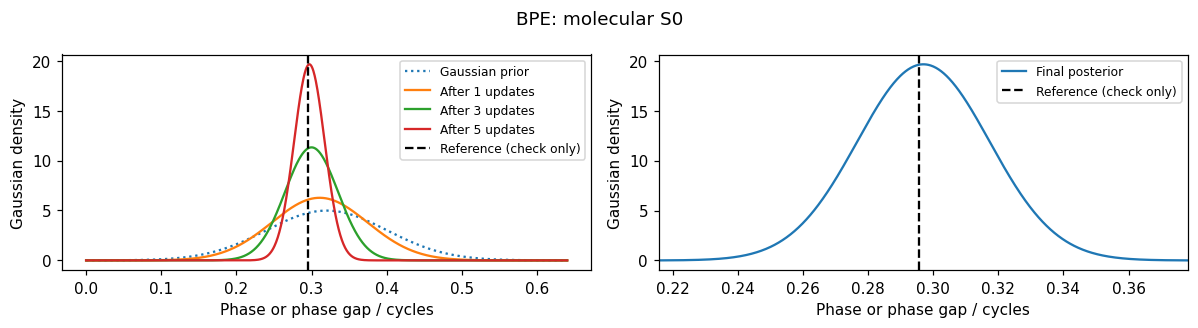

In [9]:
SHOTS = 256
SEED = 20261108
MODE = 'shots'  # 'exact'ならshot noiseなし
N_UPDATES = 5

bpe_rows = gaussian_updates(lambda L,b: ancilla_zero(ramsey_circuit(g,L,b)),
    initial_mu=.32, initial_sd=.08, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=SEED)
plot_updates(bpe_rows, PHASES[0], 'BPE: molecular S0')
print_data(bpe_rows)
print('Estimated S0 total energy / Ha:', phase_to_total(bpe_rows[-1]['posterior_mu']))

### 課題6と解答：shotsと入力状態

1. SHOTSを増やすと何が変わるか。  
   **解答：** 各候補の頻度のばらつきが減り、フィットが安定します。信号の山の幅を使うこの更新で、事後幅が必ず$1/\sqrt{\mathrm{SHOTS}}$になるわけではありません。
2. S₂を入力する場合に何を変更するか。  
   **解答：** `ramsey_circuit(g,...)`を`ramsey_circuit(e,...)`へ変え、探索事前もS₂の位相を含むものにします（例：中心0.06、SD 0.08）。真値参照線も`PHASES[1]`にします。換算式は同じです。
3. HF配置を入力して単一のGaussianを使ってよいか。  
   **解答：** HFはS₀・S₂を含み、信号には二つの位相が混ざります。単一固有状態の信号とは一般に一致せず、shotsを増やしてもモデルの不一致は消えません。

## 8．BPDE：S₀とS₂の差を直接測る

論理0/1を分子固有状態へ回す前に補助と相関させます。

```text
準備W_B:
a: |0> ──H──●──────────
            │
s: |0> ─────X──Ry(θ)───

実験全体:
a: |0> ──┌─────┐────────P(β)──┌──────┐──M_a
         │ W_B │              │ W_B† │
s: |0> ──└─────┘──[U^L]───────└──────┘─────
```

準備状態は$(|0\rangle_a|S_0\rangle_s+|1\rangle_a|S_2\rangle_s)/\sqrt2$です。
制御なしの系発展と逆準備で、
$$P_B(a=0)=[1+\cos(2\pi L\Delta+\beta)]/2
=[1+\cos((\varepsilon_E-\Delta E)t)]/2\quad(\beta=\varepsilon_Et).$$
位相差と正のエネルギー差の関係は
$$\Delta=(\phi_{S_2}-\phi_{S_0})\bmod1\approx0.74020124,\qquad
\Delta E=2\pi(1-\Delta)/\Delta t\approx1.63236378\ {\rm Ha}.$$
この換算は0<ΔE<2 Haの既知の探索枝を使います。ΔとΔEを混同しないでください。
cIや核間反発は両枝に共通で、差からは消えます。

次セルで準備と読出しを定義します。既定eta=0が厳密準備で、CNOTとcontrolled-Ry(π)の両方を照合します。
eta>0は励起側にS₀成分を混ぜる診断です。その場合、一つのギャップの山としてのフィットに偏りが生じ得ます。

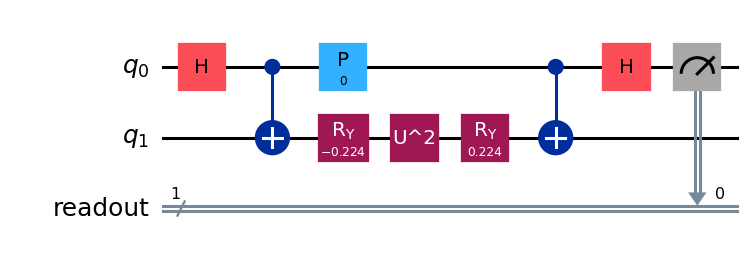

In [10]:
def preparation_b(eta=0., exact_cnot=False):
    qc=QuantumCircuit(2,name="W_B")
    qc.h(0)
    if exact_cnot:
        assert eta==0
        qc.cx(0,1)
    else:
        qc.cry(2*np.arccos(np.sqrt(eta)),0,1)
    qc.ry(theta,1)
    return qc

def bpde_circuit(eta=0.,L=1,beta=0.,exact_cnot=False,keep_constant=True):
    prep=preparation_b(eta,exact_cnot)
    qc=QuantumCircuit(2); qc.compose(prep,inplace=True)
    qc.append(evolution_gate(L,keep_constant),[1]); qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def bpde_probability(eta,L,beta):
    return .5*(1+eta*np.cos(beta)+(1-eta)*np.cos(TAU*L*GAP+beta))

# CNOTとcontrolled-Ry(pi)は |00> から同じ状態を準備するが、
# 他の入力への作用は異なる。厳密状態では同じ信号を確認する。
assert np.allclose(Statevector.from_instruction(preparation_b()).data,
                   Statevector.from_instruction(preparation_b(exact_cnot=True)).data,atol=ATOL)
draw_measured(bpde_circuit(L=2,exact_cnot=True),[0])
for eta in [0,.25,.7]:
    for L in [1,2,5]:
        for beta in [0,.31,-1.7]:
            assert np.isclose(ancilla_zero(bpde_circuit(eta,L,beta)),bpde_probability(eta,L,beta),atol=ATOL)
for L in [1,3]:
    assert np.isclose(ancilla_zero(bpde_circuit(L=L,exact_cnot=True)),bpde_probability(0,L,0),atol=ATOL)
    assert np.isclose(ancilla_zero(bpde_circuit(L=L,keep_constant=False)),bpde_probability(0,L,0),atol=ATOL)

### 8.1．BPDEでも同じGaussian更新を行う

候補を位相差$\epsilon$へ置き換え、$\beta=-2\pi L\epsilon$で走査します。
粗い事前は$\mu=0.78,\sigma=0.08$です。更新後の位相差平均を
$\Delta E=2\pi(1-\Delta)/\Delta t$で正のS₂−S₀エネルギー差へ換算します。
分布を狭める手順はBPEと同じで、絶対エネルギーを二つ推定して引く計算ではありません。

update  L   fit center    post mean     post SD    fit RMSE
  1     2    0.7403354    0.7649782    0.063057    0.01752
  2     3    0.7406459    0.7539106    0.046558    0.02142
  3     4    0.7405691    0.7482127    0.035240    0.02094
  4     5    0.7394030    0.7446451    0.027184    0.01383
  5     7    0.7401141    0.7426986    0.020531    0.02198
Simulated shots: 26880 U repetitions: 112896
Final mean: 0.7426985794748864 Gaussian SD: 0.02053052823833954
Estimated S2-S0 gap / Ha: 1.6166725049598298


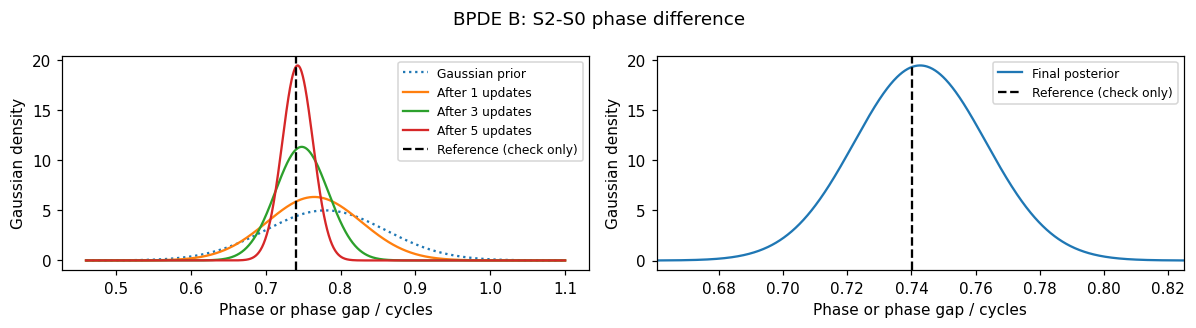

In [11]:
b_rows = gaussian_updates(lambda L,b: ancilla_zero(bpde_circuit(eta=0,L=L,beta=b)),
    initial_mu=.78, initial_sd=.08, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=83)
plot_updates(b_rows, GAP, 'BPDE B: S2-S0 phase difference')
print_data(b_rows)
print('Estimated S2-S0 gap / Ha:', phase_to_gap(b_rows[-1]['posterior_mu']))

### 課題7：BPDEの測定対象

1. この回路でS₁−S₀やT₀−S₀差を得られるか。
2. H→H+dIでBPEとBPDEはそれぞれどう変わるか。
3. eta=1では何の差を測るか。

<details><summary>解答例</summary>

1. 得られません。二つの枝に準備しているのはS₀とS₂であり、S₁/T₀は論理空間に含まれません。
2. BPEの位相は−dΔt/(2π)だけずれ、BPDEでは両枝の共通位相が消えて差は不変です。
3. 両枝がS₀となり、差0の信号です。近似状態の混入は差の直接測定でも自動的には消えません。

</details>

## 9．Fig. 1C型：全0への戻りを測る

演習1と同じ説明用$W_C=W_B\,\mathrm{SWAP}$を使います。
初期00への作用は同じでも、逆準備の最後のSWAPで情報の出る場所が変わります。
厳密準備eta=0のこの例は補助だけでは常に0、**全0の確率**は位相差に応じて変わります。

```text
|00> → W_C → [P_a(β) と U_s^L] → W_C† → M_a,M_s → 全0の回数 / 全shots
```

$A_j=\langle\widetilde S_j|U^L|\widetilde S_j\rangle$とすると
$$P_C(00)=\tfrac14|A_0+e^{i\beta}A_2|^2.$$
厳密準備ならBと同じ余弦、近似準備なら複数の固有位相の影響が残り得ます。
全0読出しは成功した部分だけで再正規化する操作ではありません。
次セルはB/Cの回路確率、補助のみと全0の読出し、近似準備の影響を比較します。
SWAPは原著の回路そのものではなく、読出しを示す例です。

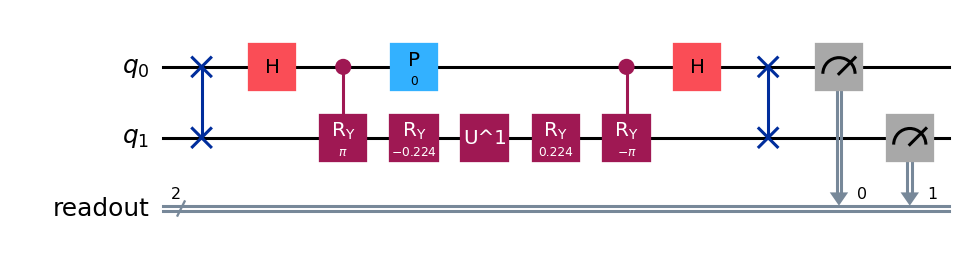

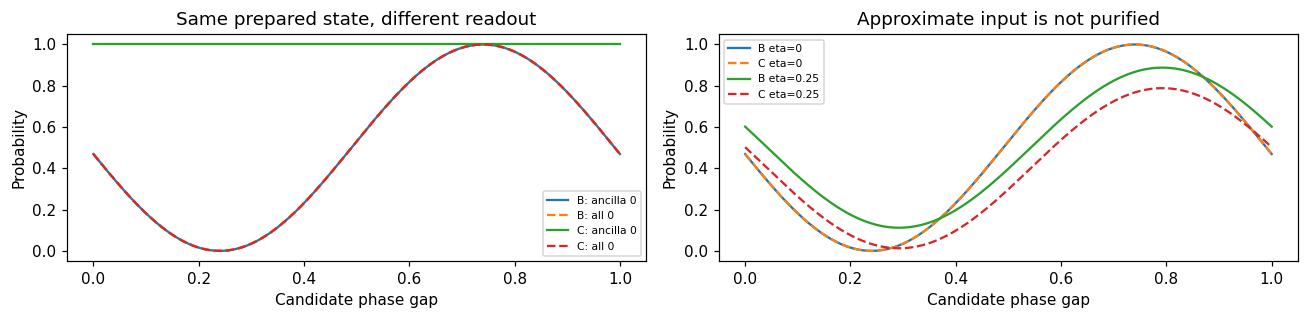

In [12]:
def preparation_c(eta=0.):
    qc=QuantumCircuit(2,name="W_C"); qc.swap(0,1)
    qc.compose(preparation_b(eta),inplace=True)
    return qc

def return_circuit(eta=0.,L=1,beta=0.,kind="C"):
    prep=preparation_c(eta) if kind=="C" else preparation_b(eta)
    qc=QuantumCircuit(2); qc.compose(prep,inplace=True)
    qc.append(evolution_gate(L),[1]); qc.p(beta,0)
    qc.compose(prep.inverse(),inplace=True)
    return qc

def readout(qc):
    sv=Statevector.from_instruction(qc)
    return float(sv.probabilities([0])[0]),float(abs(sv.data[0])**2)

def c_probability(eta,L,beta):
    ag=np.exp(1j*TAU*L*PHASES[0])
    ae=eta*ag+(1-eta)*np.exp(1j*TAU*L*PHASES[1])
    return .25*abs(ag+np.exp(1j*beta)*ae)**2

draw_measured(return_circuit(),[0,1])
assert np.allclose(Statevector.from_instruction(preparation_b()).data,Statevector.from_instruction(preparation_c()).data)
fig,axes=plt.subplots(1,2,figsize=(12,3))
for kind in ["B","C"]:
    vals=np.array([readout(return_circuit(beta=-TAU*v,kind=kind)) for v in candidates])
    axes[0].plot(candidates,vals[:,0],label=f"{kind}: ancilla 0")
    axes[0].plot(candidates,vals[:,1],ls="--",label=f"{kind}: all 0")
    if kind=="C": assert np.allclose(vals[:,0],1,atol=ATOL)
for eta in [0,.25]:
    axes[1].plot(candidates,bpde_probability(eta,1,-TAU*candidates),label=f"B eta={eta}")
    axes[1].plot(candidates,c_probability(eta,1,-TAU*candidates),ls="--",label=f"C eta={eta}")
for ax in axes: ax.set(xlabel="Candidate phase gap",ylabel="Probability"); ax.legend(fontsize=7)
axes[0].set_title("Same prepared state, different readout")
axes[1].set_title("Approximate input is not purified")
plt.tight_layout(); plt.show()
for eta in [0,.25,.7]:
    for L in [1,3,5]:
        for beta in [0,.31,-1.7]:
            for kind in ["B","C"]:
                assert np.isclose(readout(return_circuit(eta,L,beta,kind))[1],c_probability(eta,L,beta),atol=ATOL)

### 9.1．全0測定でも同じGaussian更新を行う

`readout(...)[1]`を使い、全0確率または$n_{00}/\mathrm{SHOTS}$の山をフィットします。
補助0のみの`[0]`とは区別します。B/Cの理想信号が一致することを確かめ、Cの結果もエネルギー差へ換算します。

update  L   fit center    post mean     post SD    fit RMSE
  1     2    0.7395083    0.7653134    0.063865    0.02259
  2     3    0.7392275    0.7532111    0.046759    0.01822
  3     4    0.7397793    0.7473162    0.035026    0.02008
  4     5    0.7393504    0.7440452    0.026890    0.02933
  5     7    0.7399000    0.7422464    0.020231    0.01878
Simulated shots: 26880 U repetitions: 112896
Final mean: 0.7422464243460563 Gaussian SD: 0.02023113447877138
Estimated S2-S0 gap / Ha: 1.6195134794218613


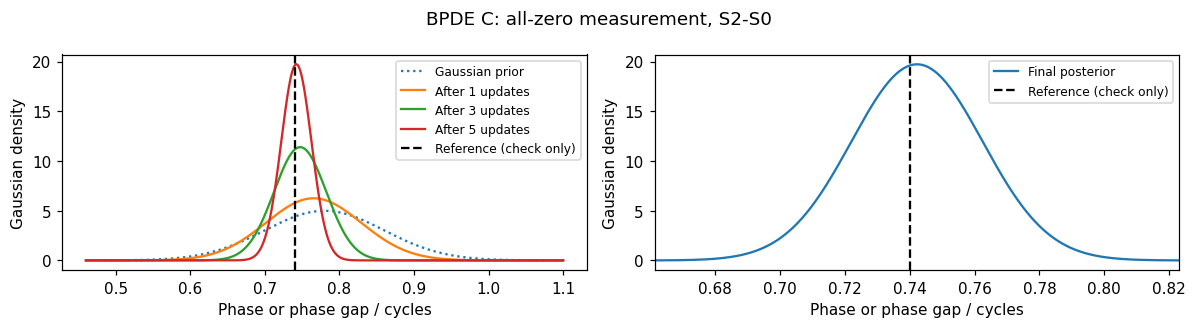

In [13]:
c_rows = gaussian_updates(lambda L,b: readout(return_circuit(L=L,beta=b,kind='C'))[1],
    initial_mu=.78, initial_sd=.08, rounds=N_UPDATES, mode=MODE, shots=SHOTS, seed=91)
plot_updates(c_rows, GAP, 'BPDE C: all-zero measurement, S2-S0')
print_data(c_rows)
print('Estimated S2-S0 gap / Ha:', phase_to_gap(c_rows[-1]['posterior_mu']))
for L in [1,2,5]:
    beta=-TAU*L*.72
    np.testing.assert_allclose(readout(return_circuit(L=L,beta=beta))[1],bpde_probability(0,L,beta),atol=ATOL)

### 課題8：同じ状態と同じ読出しを区別する

1. W_BとW_Cの準備状態が同じなら、逆準備後の補助0確率も同じか。
2. この例で全0を補助0の回数に置き換えてベイズ更新してよいか。
3. 全0測定は、近似状態を厳密固有状態へ直す操作か。

<details><summary>解答例</summary>

1. 同じではありません。時間発展後の状態に対する逆回路の作用は、準備回路全体に依存します。
2. eta=0ではCの補助は常に0で、差の情報がありません。全0という事象に対応する頻度とフィット曲線を使う必要があります。
3. 近似準備状態への戻りを測るので、厳密状態への浄化ではありません。eta>0では信号と単一ギャップモデルの不一致が残ります。

</details>

## 10．演習3への橋渡し

| 本冊で使った対応 | 次冊で変わる点 |
|---|---|
| Dg/Duの2配置 ↔ 論理1 qubit | 4スピン軌道の占有を削減なしJWで表す系4 qubit |
| RyでS₀/S₂を厳密準備 | S₁/T₀も厳密準備し、別のギャップを測る |
| Ry・Rzで厳密な1 qubit発展 | Pauli文字列の指数関数、Trotter分解を導入 |
| 補助1個と逆準備、全0測定 | 同じBPDE原理を系4＋補助1 qubitへ拡大 |

次冊では候補変数を位相差Δから正のエネルギー差ΔEへ切り替えます。
本冊の`GAP`は周期1で表す位相差、`ENERGY_GAP`はHa単位の差です。次冊の`GAPS`はHa単位です。
補正位相はβ=−2πLε（位相差候補）からβ=ε_E LΔt（エネルギー差候補）へ換算します。
さらに基本時間は本冊のΔt=1から次冊の0.1へ変わるので、Lだけでなくt=LΔtを揃えて比較します。

### 課題9：1 qubit化で残したもの・残さなかったもの

1. 1 qubit化しても電子数2とDg/Du間の電子相関は保たれるか。
2. S₁/T₀もこの1 qubit空間に含まれるか。
3. 何が厳密で、どの模型上の制約が残るか。

### 解答例（課題9：演習3への橋渡し）

1. **保たれます。** 論理0/1はどちらも2電子配置です。DgとDuの混合を残すので、相関も含みます。
2. **含まれません。** S₁/T₀は開殻配置O1/O2の別ブロックです。次冊では4スピン軌道の占有を4 qubitで表し、これらも準備します。
3. **選んだブロック内の固有状態・時間発展・1 qubitへの写像が厳密です。** 分子全体の全状態を表す符号化ではなく、核固定・STO-3G・固定構造という模型上の制約は残ります。
